In [50]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [51]:
from pathlib import Path
import pandas as pd
from matplotlib import pyplot as plt
import numpy as np
import pickle
import math
import cv2

from notebooks.imports import *
from src.utils import pmf_utils

### Config

In [52]:
from config import dir_config

raw_dir = Path(dir_config.data.raw)
processed_dir = Path(dir_config.data.processed)

me_type = "global"

### Load and Preprocess data

In [53]:
with open(Path(processed_dir, f"motion_energies_normalized/me_{me_type}.pkl"), "rb") as f:
	motion_energy_dict = pickle.load(f)

data = pd.read_csv(Path(processed_dir, "valid_data.csv"), index_col=None)
print(len(motion_energy_dict))
data

113874


,agg_code,idx_session,data_source,subject_id,session_id,idx_valid_trial,idx_correction,is_correction_trial,signed_coherence,target,choice,reaction_time,outcome,reward_amount,fixation_duration,stimulus_duration,reinforcement_duration,intertrial_delay,stimulus_seed,is_pulse_trial,pulse_onset,pulse_duration,pulse_coherence,pulse_type
0,DBM11_10_1_1,0,uw,DBM11,10_1,1,0,False,100,1.0,1,1.080817,1.0,1.5,0.530901,25.0,0.0,0.500000,612658,True,0.416750,0.066680,-100.0,-3
1,DBM11_10_1_2,0,uw,DBM11,10_1,2,0,False,100,1.0,0,0.469520,0.0,NaN,0.577326,25.0,0.0,13.689771,463182,False,0.416750,0.066680,100.0,0
2,DBM11_10_1_3,0,uw,DBM11,10_1,3,0,False,-100,-1.0,0,2.171707,1.0,1.5,0.556890,25.0,0.0,0.500000,165712,True,0.416750,0.066680,100.0,3
3,DBM11_10_1_4,0,uw,DBM11,10_1,4,0,False,-100,-1.0,0,0.476003,1.0,1.5,0.548262,25.0,0.0,0.500000,418800,False,0.050010,0.066680,-100.0,0
4,DBM11_10_1_5,0,uw,DBM11,10_1,5,0,False,-100,-1.0,0,0.971870,1.0,1.5,0.561377,25.0,0.0,0.500000,372882,False,0.233380,0.066680,-100.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113869,PSUIM9_9_1_346,300,ucla,PSUIM9,9_1,346,0,False,18,1.0,1,1.108688,1.0,2.6,1.000000,60.0,0.5,0.250000,346,True,0.029568,0.050560,100.0,1
113870,PSUIM9_9_1_347,300,ucla,PSUIM9,9_1,347,0,False,36,1.0,1,1.598707,1.0,2.6,1.000000,60.0,0.5,0.250000,347,False,NaN,NaN,NaN,0
113871,PSUIM9_9_1_348,300,ucla,PSUIM9,9_1,348,0,False,-9,-1.0,1,2.292042,0.0,0.0,1.000000,60.0,1.5,0.252608,348,False,NaN,NaN,NaN,0
113872,PSUIM9_9_1_349,300,ucla,PSUIM9,9_1,349,0,False,36,1.0,1,1.706793,1.0,2.6,1.000000,60.0,0.5,0.250000,349,True,0.240538,0.050291,100.0,2


In [54]:
missing_in_motion_data = set(data.agg_code) - set(motion_energy_dict)
extra_in_motion_data = set(motion_energy_dict) - set(data.agg_code)

assert len(missing_in_motion_data) == 0, f"Missing keys in motion_data_dict: {missing_in_motion_data}"
assert len(extra_in_motion_data) == 0, f"Extra keys in motion_data_dict: {extra_in_motion_data}"


### Utils

In [55]:
# Define mapping from pulse_type to descriptive variable names
pulse_mapping = {
    -3: "late_left_pulse",
    -2: "middle_left_pulse",
    -1: "early_left_pulse",
    0: "control",
    1: "early_right_pulse",
    2: "middle_right_pulse",
    3: "late_right_pulse",
    }


In [ ]:
# Define mapping from pulse_type to descriptive variable names
def get_motion_data(trial_indices, motion_energy_dict):
	# List to store the motion data
	motion_data_array = []

	# Keep track of the max shape of the motion data
	max_shape = (0, 0, 0)  # Initialize with zeros, assuming 3 dimensions (for safety)

	for i in trial_indices:
		try:
			if i in motion_energy_dict.keys():
				motion_data_array.append(motion_energy_dict[i])
				max_shape = tuple(map(max, zip(max_shape, motion_energy_dict[i].shape)))
			else:
				print(f"Warning: Index {i} not found in motion_data_dict.")
		except Exception as e:
			print(f"Error processing index {i}: {e}")

	padded_motion_data = []
	for data in motion_data_array:
		if data.ndim == 1:
			padded_data = np.pad(data, (0, max_shape[0] - data.shape[0]), mode="constant")
		elif data.ndim == 2:
			padded_data = np.pad(data, [(0, max_shape[0] - data.shape[0]), (0, max_shape[1] - data.shape[1])], mode="constant")
		elif data.ndim == 3:
			padded_data = np.pad(data, [(0, max_shape[0] - data.shape[0]), (0, max_shape[1] - data.shape[1]), (0, max_shape[2] - data.shape[2])], mode="constant")
		else:
			raise ValueError(f"Unexpected number of dimensions in motion data: {data.ndim}")
		padded_motion_data.append(padded_data)

	motion_data_array = np.array(padded_motion_data)
	return motion_data_array

### Code

In [57]:
pulse_type = data.pulse_type.unique()

for pt in sorted(pulse_type):
	print(f"{pt}: {pulse_mapping.get(pt, None)}")

-3: late_left_pulse
-2: middle_left_pulse
-1: early_left_pulse
0: control
1: early_right_pulse
2: middle_right_pulse
3: late_right_pulse


In [ ]:
# note indices for each pulse_type and each signed_coherence under each pulse_type
indices = {}
for pt in pulse_type:
	indices[pt] = {}
	for sc in data.signed_coherence.unique():
		indices[pt][sc] = data[(data.pulse_type == pt) & (data.signed_coherence == sc)].agg_code.values

In [ ]:
# Initialize pulse_energy dictionary as {pulse_time: {coh: motion_array}}
pulse_energy = {}

# Loop through each pulse type and its corresponding coherences
for pt in pulse_type:
	pulse_time = pulse_mapping.get(pt, None)
	if pulse_time is None:
		print(f"⚠️ Unknown pulse_type {pt}, skipping.")
		continue

	pulse_energy[pulse_time] = {}

	for coh in indices.get(pt, {}):
		motion_energy = get_motion_data(indices[pt][coh], motion_energy_dict)

		if motion_energy.size > 0:
			pulse_energy[pulse_time][coh] = motion_energy
		else:
			print(f"⚠️ Skipping pulse_time {pulse_time}, coherence {coh}: No valid data found")

# # # Optionally: Print the structure to verify
# for pulse_time, coherence_data in pulse_energy.items():
#     print(f"Pulse Time: {pulse_time}")
#     for coh, motion_data in coherence_data.items():
#         print(f"  Coherence {coh}: Data shape {motion_data.shape}")

# # Example of how to access the data:
# # To access the motion data for "early_left_pulse" at coherence 1
# early_left_pulse_coh1_data = pulse_energy.get("early_left_pulse", {}).get(1, np.full((max_length,), np.nan))

# # Print the length of a specific pulse data to verify
# print(f"Early left pulse coherence 1 data length: {len(early_left_pulse_coh1_data)}")


⚠️ Skipping pulse_time late_left_pulse, coherence -100: No valid data found
⚠️ Skipping pulse_time late_right_pulse, coherence 100: No valid data found
⚠️ Skipping pulse_time middle_left_pulse, coherence -100: No valid data found
⚠️ Skipping pulse_time middle_right_pulse, coherence 100: No valid data found
⚠️ Skipping pulse_time early_left_pulse, coherence -100: No valid data found
⚠️ Skipping pulse_time early_right_pulse, coherence 100: No valid data found


In [87]:
def plot_pulse_energy(pulse_energy, pulse_type, coh, ax=None):
	try:
		mean = np.nanmean(pulse_energy[pulse_type][coh], axis=0)
		std = np.nanstd(pulse_energy[pulse_type][coh], axis=0)
		x = np.arange(mean.shape[0])

		if ax is None:
			plt.plot(x, mean, label=pulse_type)
			plt.fill_between(x, mean - std, mean + std, alpha=0.3)
		else:
			ax.plot(x, mean, label=pulse_type)
			ax.fill_between(x, mean - std, mean + std, alpha=0.3)

	except KeyError:
		print(f"⚠️ {pulse_type} with coherence {coh} not found.")


def plot_all_pulses(ax, pulse_energy, coh, title):
	pulses = ["early_left_pulse", "middle_left_pulse", "late_left_pulse", "early_right_pulse", "middle_right_pulse", "late_right_pulse"]
	for pulse in pulses:
		plot_pulse_energy(pulse_energy, pulse, coh, ax=ax)
	ax.set_title(title, fontsize=16)
	ax.set_ylim([-1, 1])
	ax.set_xlim([0, 60])
	xticks = np.arange(0, 61, 10)
	xticks_msec = np.round(xticks / 60, 2) * 100
	ax.set_xticks(xticks)
	ax.set_xticklabels(xticks_msec.astype(int))
	ax.set_xlabel("Time (msec)")
	ax.set_ylabel("Motion Energy")
	ax.legend()

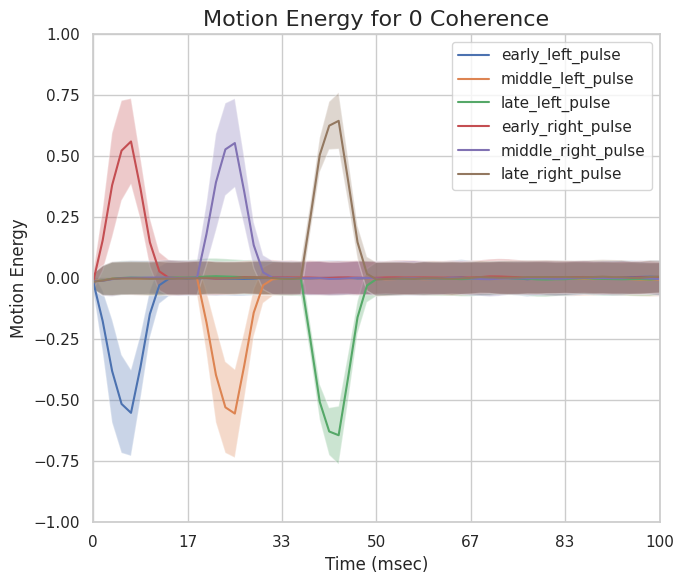

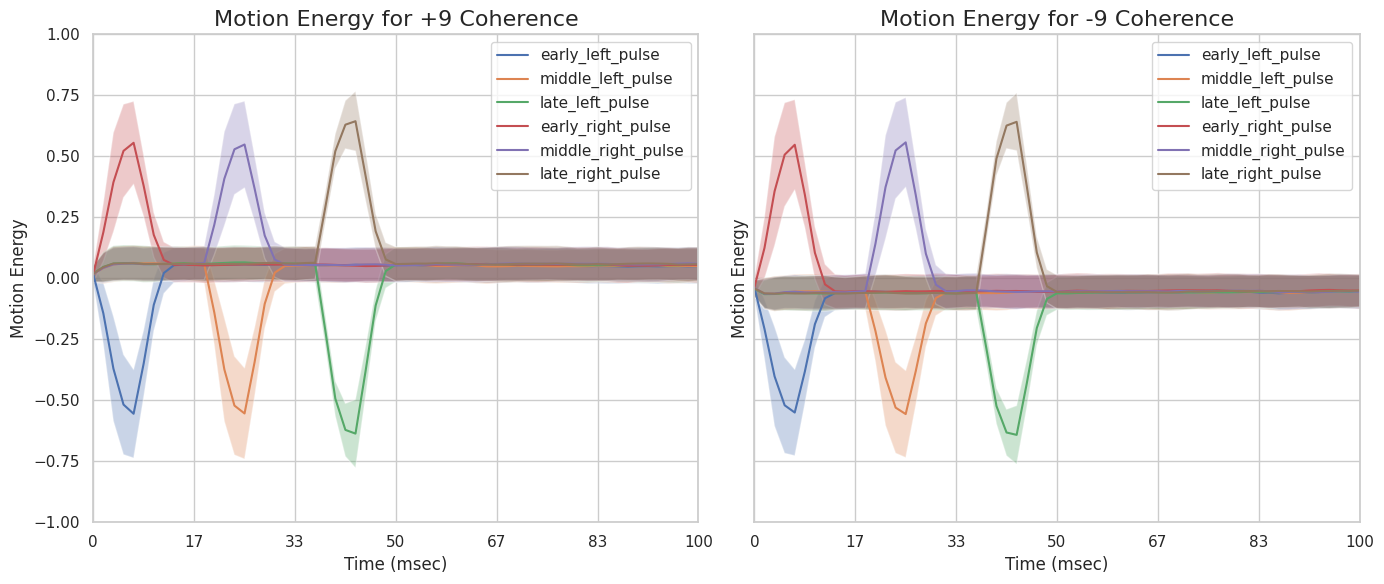

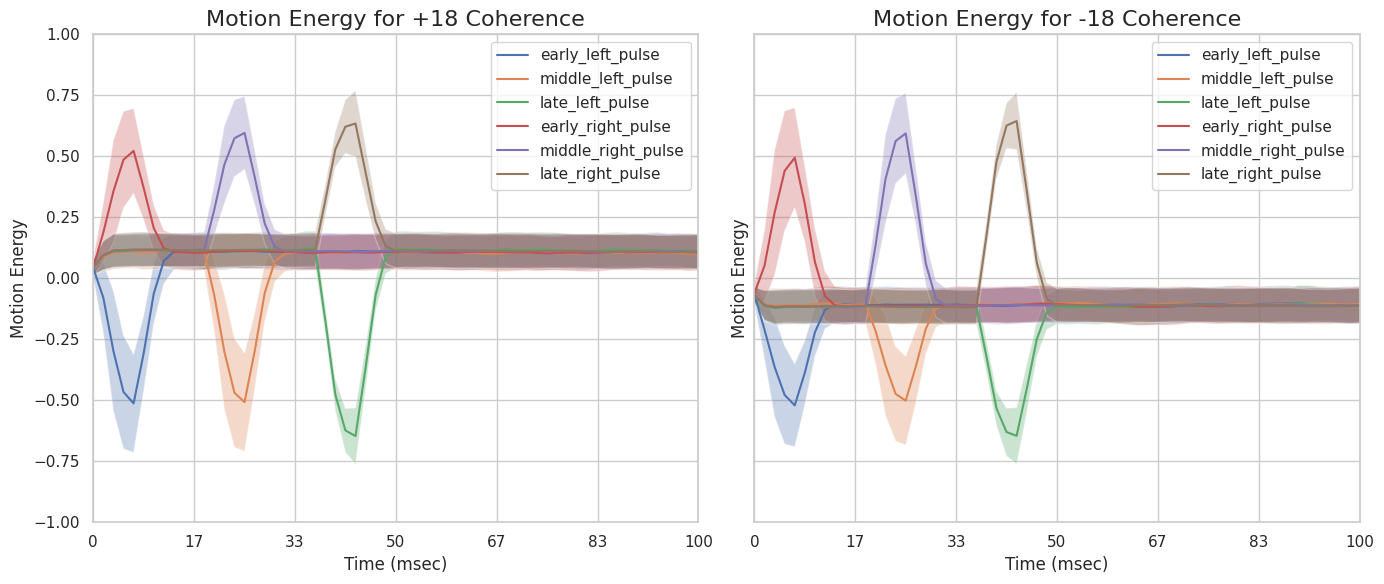

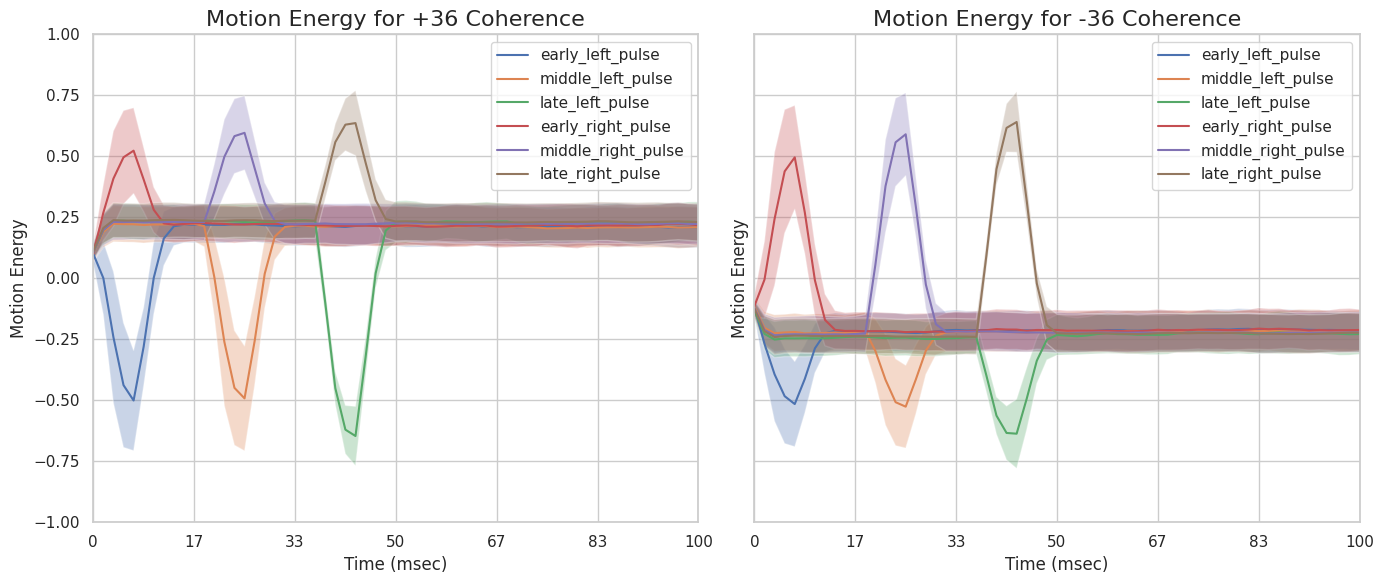

⚠️ early_right_pulse with coherence 100 not found.
⚠️ middle_right_pulse with coherence 100 not found.
⚠️ late_right_pulse with coherence 100 not found.
⚠️ early_left_pulse with coherence -100 not found.
⚠️ middle_left_pulse with coherence -100 not found.
⚠️ late_left_pulse with coherence -100 not found.


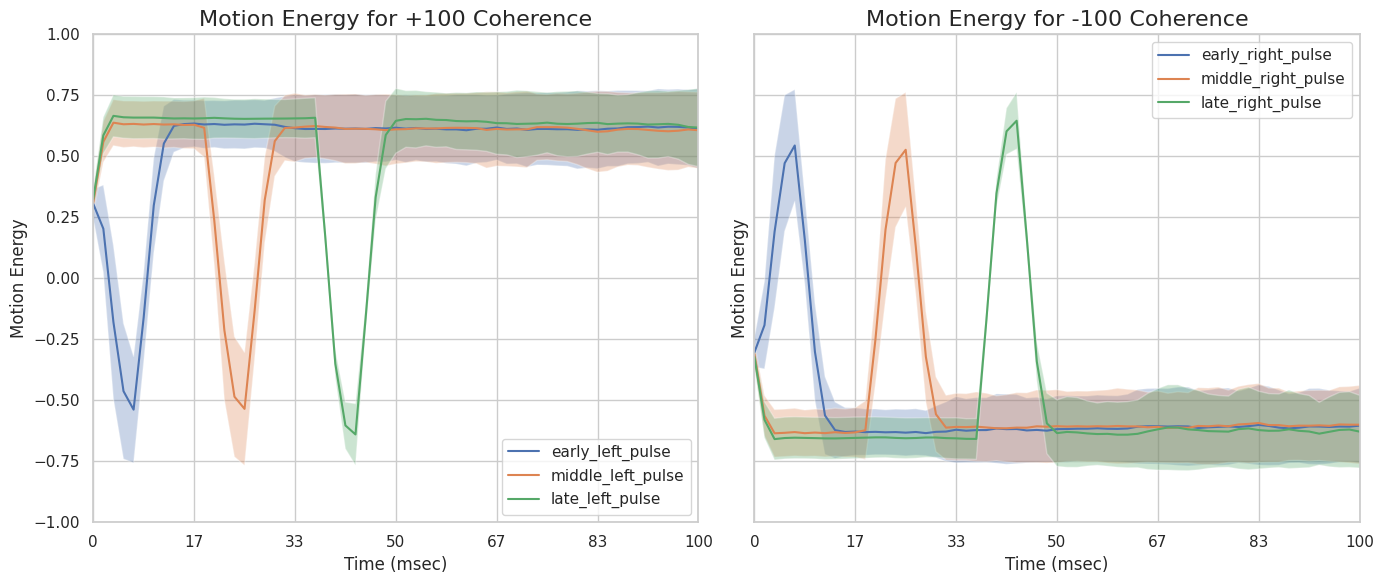

In [91]:
unique_coherences = np.unique(np.abs(data.signed_coherence))
for coh in unique_coherences:
	if coh != 0:
		fig, axs = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
		plot_all_pulses(axs[0], pulse_energy, +coh, f"Motion Energy for +{coh} Coherence")
		plot_all_pulses(axs[1], pulse_energy, -coh, f"Motion Energy for -{coh} Coherence")
		plt.tight_layout()
		plt.show()
	else:
		fig, ax = plt.subplots(figsize=(7, 6))
		plot_all_pulses(ax, pulse_energy, 0, f"Motion Energy for {coh} Coherence")
		plt.tight_layout()
		plt.show()


---
---